In [1]:
import os
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

print("All imports completed successfully!")
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("GPU available:", torch.cuda.is_available())

All imports completed successfully!
PyTorch version: 2.14.0+cpu
OpenCV version: 4.10.0
NumPy version: 2.4.6
GPU available: False


In [1]:
import urllib.request
import zipfile
from pathlib import Path

dataset_url = (
    "https://storage.googleapis.com/"
    "tensorflow-1-public/course2/cats_and_dogs_filtered.zip"
)

zip_path = Path("cats_and_dogs_filtered.zip")
dataset_dir = Path("cats_and_dogs_filtered")

if not dataset_dir.exists():
    print("Downloading dataset...")

    try:
        urllib.request.urlretrieve(dataset_url, zip_path)
        print("Download complete. Extracting dataset...")

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(".")

        print("Dataset extracted successfully!")

    except Exception as e:
        print("Download or extraction failed:", e)

else:
    print("Dataset already exists. Skipping download.")



Dataset already exists. Skipping download.


In [2]:
print("Dataset location:", dataset_dir.resolve())

Dataset location: C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cats_and_dogs_filtered


In [3]:
from pathlib import Path

dataset_dir = Path("cats_and_dogs_filtered")

train_dir = dataset_dir / "train"
val_dir = dataset_dir / "validation"

for folder in [
    train_dir / "cats",
    train_dir / "dogs",
    val_dir / "cats",
    val_dir / "dogs"
]:
    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print(f"{folder}: {len(images)} images")

cats_and_dogs_filtered\train\cats: 1000 images
cats_and_dogs_filtered\train\dogs: 1000 images
cats_and_dogs_filtered\validation\cats: 500 images
cats_and_dogs_filtered\validation\dogs: 500 images


Image path: cats_and_dogs_filtered\train\cats\cat.0.jpg
Image shape: (374, 500, 3)
Data type: uint8


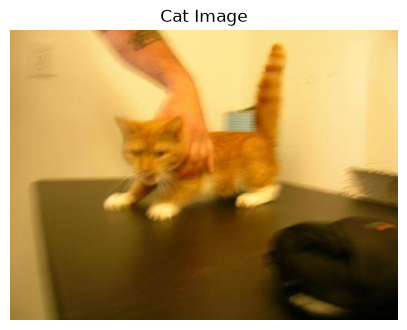

In [6]:
import cv2
import matplotlib.pyplot as plt

cat_images = list((train_dir / "cats").glob("*.jpg"))

image_path = str(cat_images[0])
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded.")

print("Image path:", image_path)
print("Image shape:", image.shape)
print("Data type:", image.dtype)

# OpenCV uses BGR; Matplotlib expects RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(image_rgb)
plt.title("Cat Image")
plt.axis("off")
plt.show()

Original shape: (374, 500, 3)
Resized shape: (128, 128, 3)
Normalized range: 0.0 to 1.0


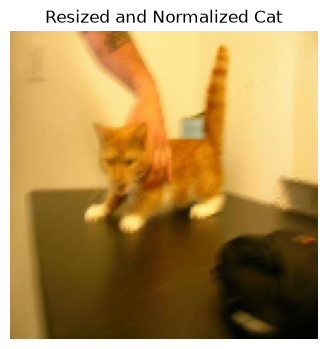

In [7]:
import numpy as np

IMG_SIZE = 128

resized_image = cv2.resize(
    image_rgb,
    (IMG_SIZE, IMG_SIZE)
)

normalized_image = resized_image.astype(np.float32) / 255.0

print("Original shape:", image_rgb.shape)
print("Resized shape:", resized_image.shape)
print("Normalized range:",
      normalized_image.min(),
      "to",
      normalized_image.max())

plt.figure(figsize=(4, 4))
plt.imshow(normalized_image)
plt.title("Resized and Normalized Cat")
plt.axis("off")
plt.show()

In [8]:
import torch
import numpy as np

# Change HWC to CHW
image_chw = np.transpose(normalized_image, (2, 0, 1)).copy()

# Convert NumPy array to PyTorch tensor
image_tensor = torch.from_numpy(image_chw)

print("Tensor shape:", image_tensor.shape)
print("Data type:", image_tensor.dtype)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Tensor shape: torch.Size([3, 128, 128])
Data type: torch.float32
Minimum value: 0.0
Maximum value: 1.0


In [9]:
def preprocess_image(image_path,img_size=128):
    #Read image
    image=cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    # BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize
    image = cv2.resize(image, (img_size, img_size))

    # Normalize
    image = image.astype(np.float32) / 255.0

    # HWC to CHW
    image = np.transpose(image, (2, 0, 1)).copy()

    # Convert to tensor
    image = torch.from_numpy(image)

    return image

In [10]:

test_tensor = preprocess_image(image_path)

print("Shape:", test_tensor.shape)
print("Type:", test_tensor.dtype)


Shape: torch.Size([3, 128, 128])
Type: torch.float32


In [11]:
from pathlib import Path
from torch.utils.data import Dataset
import torch
import cv2
import numpy as np

class CatDogDataset(Dataset):

    def __init__(self, folder, img_size=128):
        self.folder = Path(folder)
        self.img_size = img_size
        self.classes = ["cats", "dogs"]
        self.samples = []

        extensions = {".jpg", ".jpeg", ".png"}

        for label, class_name in enumerate(self.classes):
            class_folder = self.folder / class_name

            for image_path in class_folder.iterdir():
                if image_path.suffix.lower() in extensions:
                    self.samples.append((image_path, label))

        if len(self.samples) == 0:
            raise ValueError(f"No images found in {self.folder}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(
            image, (self.img_size, self.img_size)
        )

        image = image.astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1)).copy()

        image_tensor = torch.from_numpy(image)
        label_tensor = torch.tensor(label, dtype=torch.long)

        return image_tensor, label_tensor

In [12]:
train_dataset = CatDogDataset(train_dir, img_size=128)
val_dataset = CatDogDataset(val_dir, img_size=128)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Class mapping:", {"cats": 0, "dogs": 1})

Training images: 2000
Validation images: 1000
Class mapping: {'cats': 0, 'dogs': 1}


In [13]:
sample_image,sample_label=train_dataset[0]
print("Image shape:", sample_image.shape)
print("Image type:", sample_image.dtype)
print("Label:", sample_label.item())
print("Label name:", ["Cat", "Dog"][sample_label.item()])

Image shape: torch.Size([3, 128, 128])
Image type: torch.float32
Label: 0
Label name: Cat


In [14]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

DataLoaders created successfully!
Training batches: 125
Validation batches: 63


In [15]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels:", labels.tolist())
print("Pixel range:", images.min().item(), "to", images.max().item())

Batch image shape: torch.Size([16, 3, 128, 128])
Batch label shape: torch.Size([16])
Labels: [0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0]
Pixel range: 0.0 to 1.0


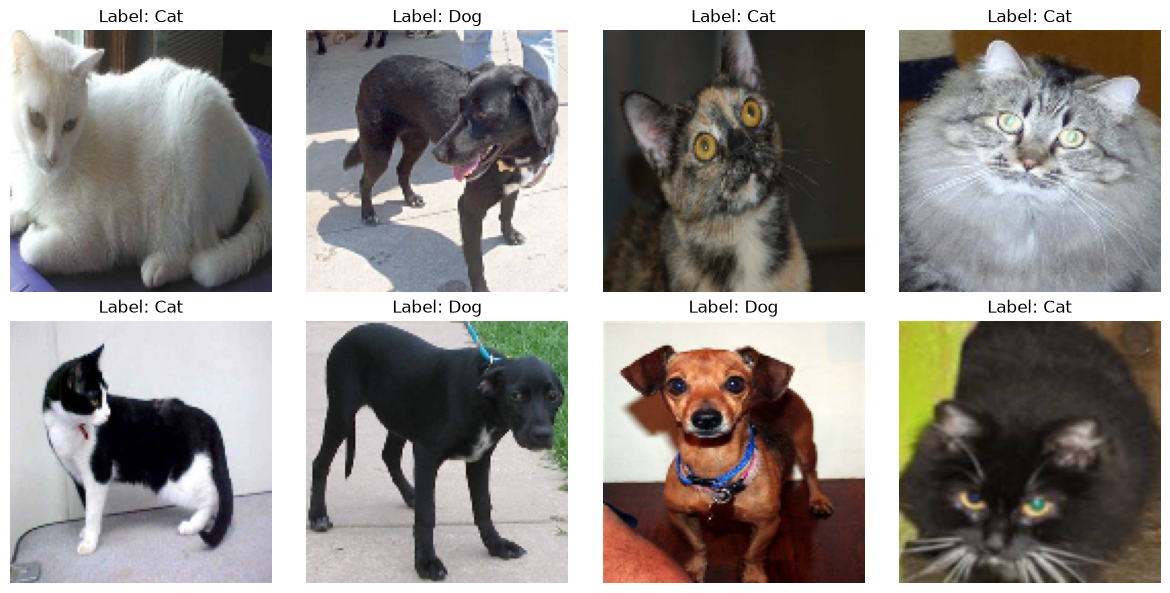

In [16]:
import matplotlib.pyplot as plt

# Get one batch
images, labels = next(iter(train_loader))

class_names = ["Cat", "Dog"]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # PyTorch: CHW -> HWC for displaying with Matplotlib
    image = images[i].permute(1, 2, 0).numpy()

    label = labels[i].item()

    ax.imshow(image)
    ax.set_title(f"Label: {class_names[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
from collections import Counter

train_counts = Counter(label for _, label in train_dataset.samples)
val_counts = Counter(label for _, label in val_dataset.samples)

print("Training class distribution:")
print("Cats:", train_counts[0])
print("Dogs:", train_counts[1])

print("\nValidation class distribution:")
print("Cats:", val_counts[0])
print("Dogs:", val_counts[1])

Training class distribution:
Cats: 1000
Dogs: 1000

Validation class distribution:
Cats: 500
Dogs: 500


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Using device: cpu
Training batches: 125
Validation batches: 63


In [20]:
class CatDogCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 input channels -> 16 feature maps
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2: 16 -> 32 feature maps
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3: 32 -> 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Standardize the feature-map size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = CatDogCNN().to(device)

print(model)

CatDogCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [21]:
images, labels = next(iter(train_loader))
images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Number of model parameters:",
      sum(p.numel() for p in model.parameters()))

Input shape: torch.Size([16, 3, 128, 128])
Output shape: torch.Size([16, 2])
Number of model parameters: 155042


In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")

Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001


In [34]:

# 4. Training settings
EPOCHS = 20
best_val_acc = 0.0

best_model_path = Path("cat_dog_cnn_best.pth")

# Store metrics for graphs
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# 5. Training and validation loop
for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Calculate total training loss
        running_loss += loss.item() * images.size(0)

        # Calculate training accuracy
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Predict without updating weights
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            # Calculate validation accuracy
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if epoch_val_acc > best_val_acc:

        best_val_acc = epoch_val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": best_val_acc,
            "img_size": 128,
            "class_names": ["Cat", "Dog"]
        }, best_model_path)

        saved_message = " | Best model saved!"
    else:
        saved_message = ""

    # -------------------------
    # DISPLAY RESULTS
    # -------------------------
    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_acc:.2%}"
        f"{saved_message}"
    )

# 6. Print final best result
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

print("\nTraining completed!")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Saved model:", best_model_path.resolve())


Epoch [1/20] | Train Loss: 0.0802 | Train Accuracy: 96.65% | Val Loss: 1.2080 | Val Accuracy: 73.10% | Best model saved!
Epoch [2/20] | Train Loss: 0.0520 | Train Accuracy: 98.05% | Val Loss: 1.3634 | Val Accuracy: 74.20% | Best model saved!
Epoch [3/20] | Train Loss: 0.0810 | Train Accuracy: 96.90% | Val Loss: 1.1733 | Val Accuracy: 73.80%
Epoch [4/20] | Train Loss: 0.0706 | Train Accuracy: 97.65% | Val Loss: 1.1586 | Val Accuracy: 73.30%
Epoch [5/20] | Train Loss: 0.0482 | Train Accuracy: 98.35% | Val Loss: 1.3206 | Val Accuracy: 73.10%
Epoch [6/20] | Train Loss: 0.0624 | Train Accuracy: 97.75% | Val Loss: 1.1995 | Val Accuracy: 72.70%
Epoch [7/20] | Train Loss: 0.0433 | Train Accuracy: 98.80% | Val Loss: 1.3641 | Val Accuracy: 73.20%
Epoch [8/20] | Train Loss: 0.0402 | Train Accuracy: 98.60% | Val Loss: 1.3202 | Val Accuracy: 73.10%
Epoch [9/20] | Train Loss: 0.0541 | Train Accuracy: 97.80% | Val Loss: 1.3972 | Val Accuracy: 73.50%
Epoch [10/20] | Train Loss: 0.0657 | Train Accuracy

In [35]:
checkpoint = torch.load(
    "cat_dog_cnn_best.pth",
    map_location=device,
    weights_only=True
)

print("Best epoch:", checkpoint["epoch"])
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Image size:", checkpoint["img_size"])
print("Classes:", checkpoint["class_names"])

Best epoch: 20
Best validation accuracy: 75.30%
Image size: 128
Classes: ['Cat', 'Dog']


In [36]:

import torch
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load checkpoint
checkpoint = torch.load(
    "cat_dog_cnn_best.pth",
    map_location=device,
    weights_only=True
)

# Recreate the model architecture
model = CatDogCNN().to(device)

# Load saved weights
model.load_state_dict(checkpoint["model_state_dict"])

# Set evaluation mode
model.eval()

class_names = checkpoint["class_names"]
IMG_SIZE = checkpoint["img_size"]

print("Model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Classes:", class_names)


Device: cpu
Model loaded successfully!
Best epoch: 20
Validation accuracy: 75.30%
Classes: ['Cat', 'Dog']


In [37]:

dataset_dir = Path(
    r"C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cats_and_dogs_filtered"
)

# Select the first cat image from validation
image_files = list((dataset_dir / "validation" / "cats").glob("*"))

if not image_files:
    raise FileNotFoundError("No cat images found in validation/cats")

image_path = image_files[0]

print("Image selected:", image_path)


Image selected: C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cats_and_dogs_filtered\validation\cats\cat.2000.jpg


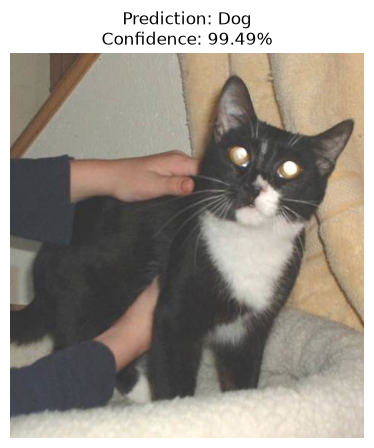

Predicted class: Dog
Confidence: 99.49%


In [38]:

def predict_cat_dog(image_path):
    # Read image
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    # OpenCV BGR -> RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize and normalize
    resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE))
    normalized = resized.astype(np.float32) / 255.0

    # Convert HWC -> CHW
    image_array = np.transpose(normalized, (2, 0, 1)).copy()

    # Convert to tensor and add batch dimension
    image_tensor = torch.from_numpy(image_array)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Predict
    model.eval()
    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)

    predicted_index = probabilities.argmax(dim=1).item()
    predicted_class = class_names[predicted_index]
    confidence = probabilities[0, predicted_index].item() * 100

    # Display image and result
    plt.figure(figsize=(5, 5))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_class, confidence


prediction, confidence = predict_cat_dog(image_path)


In [39]:

print("Image path:", image_path)
print("Actual label: Cat")
print("Predicted label:", prediction)
print(f"Predicted confidence: {confidence:.2f}%")

# Display probability for each class
image = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE))

image_array = resized.astype(np.float32) / 255.0
image_array = np.transpose(image_array, (2, 0, 1)).copy()
image_tensor = torch.from_numpy(image_array).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[i].item() * 100:.2f}%")


Image path: C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cats_and_dogs_filtered\validation\cats\cat.2000.jpg
Actual label: Cat
Predicted label: Dog
Predicted confidence: 99.49%
Cat: 0.51%
Dog: 99.49%


Validation accuracy: 75.30%

Classification report:
              precision    recall  f1-score   support

         Cat       0.80      0.67      0.73       500
         Dog       0.72      0.83      0.77       500

    accuracy                           0.75      1000
   macro avg       0.76      0.75      0.75      1000
weighted avg       0.76      0.75      0.75      1000



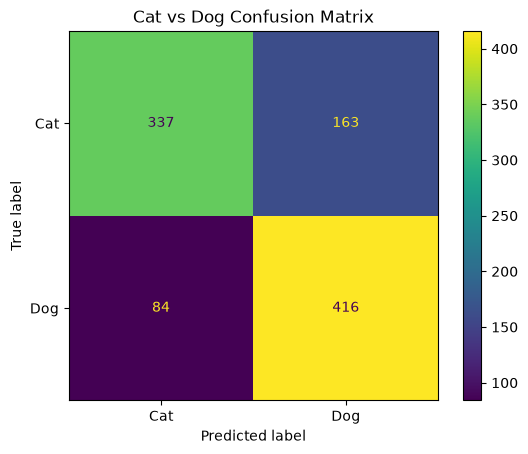

In [40]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.2%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)
display.plot()
plt.title("Cat vs Dog Confusion Matrix")
plt.show()


In [41]:

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
from pathlib import Path
import random

class AugmentedCatDogDataset(Dataset):
    def __init__(self, folder, img_size=128, augment=False):
        self.folder = Path(folder)
        self.img_size = img_size
        self.augment = augment
        self.classes = ["cats", "dogs"]
        self.samples = []
        extensions = {".jpg", ".jpeg", ".png"}

        for label, class_name in enumerate(self.classes):
            class_folder = self.folder / class_name

            for image_path in class_folder.iterdir():
                if image_path.suffix.lower() in extensions:
                    self.samples.append((image_path, label))

        if not self.samples:
            raise ValueError(f"No images found in {self.folder}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size, self.img_size))

        if self.augment:
            # Random horizontal flip
            if random.random() < 0.5:
                image = cv2.flip(image, 1)

            # Small random rotation
            angle = random.uniform(-15, 15)
            matrix = cv2.getRotationMatrix2D(
                (self.img_size / 2, self.img_size / 2),
                angle,
                1.0
            )
            image = cv2.warpAffine(
                image,
                matrix,
                (self.img_size, self.img_size),
                borderMode=cv2.BORDER_REFLECT_101
            )

        image = image.astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1)).copy()

        return (
            torch.from_numpy(image),
            torch.tensor(label, dtype=torch.long)
        )

print("Augmented dataset class defined successfully!")


Augmented dataset class defined successfully!


In [42]:

from torch.utils.data import DataLoader

train_dataset = AugmentedCatDogDataset(
    train_dir,
    img_size=128,
    augment=True
)

val_dataset = AugmentedCatDogDataset(
    val_dir,
    img_size=128,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Data augmentation enabled for training only.")


Training images: 2000
Validation images: 1000
Data augmentation enabled for training only.


Using device: cpu
Epoch [1/20] | Train Loss: 0.6926 | Train Acc: 52.60% | Val Loss: 0.6872 | Val Acc: 60.50% | Best model saved!
Epoch [2/20] | Train Loss: 0.6780 | Train Acc: 57.35% | Val Loss: 0.6521 | Val Acc: 61.10% | Best model saved!
Epoch [3/20] | Train Loss: 0.6447 | Train Acc: 63.75% | Val Loss: 0.6317 | Val Acc: 66.60% | Best model saved!
Epoch [4/20] | Train Loss: 0.6121 | Train Acc: 66.55% | Val Loss: 0.5988 | Val Acc: 67.60% | Best model saved!
Epoch [5/20] | Train Loss: 0.5955 | Train Acc: 69.45% | Val Loss: 0.6076 | Val Acc: 68.20% | Best model saved!
Epoch [6/20] | Train Loss: 0.5856 | Train Acc: 69.40% | Val Loss: 0.5903 | Val Acc: 68.00%
Epoch [7/20] | Train Loss: 0.5764 | Train Acc: 70.15% | Val Loss: 0.5951 | Val Acc: 67.30%
Epoch [8/20] | Train Loss: 0.5623 | Train Acc: 71.10% | Val Loss: 0.5846 | Val Acc: 68.10%
Epoch [9/20] | Train Loss: 0.5670 | Train Acc: 70.90% | Val Loss: 0.5663 | Val Acc: 69.00% | Best model saved!
Epoch [10/20] | Train Loss: 0.5482 | Train 

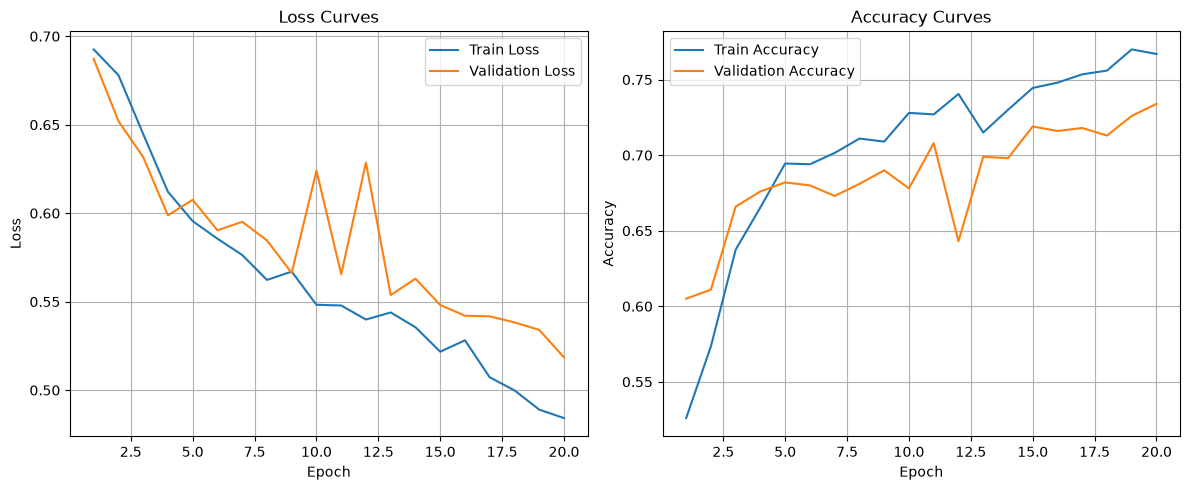

In [43]:

import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Start a fresh model
model = CatDogCNN().to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training settings
EPOCHS = 20
best_val_acc = 0.0
best_model_path = Path("cat_dog_cnn_augmented_best.pth")

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = train_loss_sum / train_total
    epoch_train_acc = train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss_sum / val_total
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # =========================
    # SAVE BEST CHECKPOINT
    # =========================
    saved_message = ""

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": best_val_acc,
            "img_size": 128,
            "class_names": ["Cat", "Dog"]
        }, best_model_path)

        saved_message = " | Best model saved!"

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2%}"
        f"{saved_message}"
    )

# =========================
# REPORT BEST RESULT
# =========================
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

print("\nTraining complete!")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Saved model:", best_model_path.resolve())

# =========================
# PLOT RESULTS
# =========================
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label="Train Accuracy")
plt.plot(epochs_range, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Validation accuracy: 73.40%

Classification report:
              precision    recall  f1-score   support

         Cat       0.73      0.74      0.74       500
         Dog       0.74      0.72      0.73       500

    accuracy                           0.73      1000
   macro avg       0.73      0.73      0.73      1000
weighted avg       0.73      0.73      0.73      1000



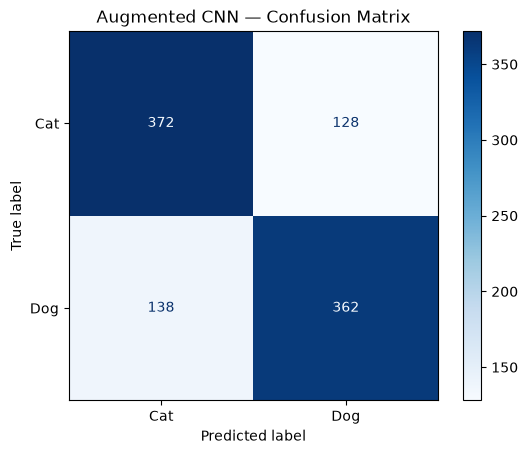

In [44]:

import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best augmented checkpoint
checkpoint = torch.load(
    "cat_dog_cnn_augmented_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().tolist())

print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.2%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Augmented CNN — Confusion Matrix")
plt.show()


In [45]:

import torch

print("PyTorch version:", torch.__version__)

try:
    import torchvision
    print("Torchvision version:", torchvision.__version__)
    print("Torchvision is ready for transfer learning!")
except ImportError:
    print("Torchvision is not installed.")


PyTorch version: 2.14.0+cpu
Torchvision version: 0.29.0+cpu
Torchvision is ready for transfer learning!


In [46]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Dataset paths
dataset_dir = Path(
    r"C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cats_and_dogs_filtered"
)
train_dir = dataset_dir / "train"
val_dir = dataset_dir / "validation"

# Load pretrained weights and recommended normalization values
weights = ResNet18_Weights.DEFAULT

# Training preprocessing and augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation preprocessing: no random augmentation
val_transform = weights.transforms()

# Load images from folders
train_dataset = datasets.ImageFolder(
    root=str(train_dir),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=str(val_dir),
    transform=val_transform
)

# Loaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

class_names = train_dataset.classes

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Verify a batch
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)


Device: cpu
Classes: ['cats', 'dogs']
Training images: 2000
Validation images: 1000
Batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])


In [47]:

# Load pretrained ResNet18
model = resnet18(weights=weights)

# Freeze pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Replace final layer for 2 classes
model.fc = nn.Linear(model.fc.in_features, 2)

# Move model to device
model = model.to(device)

# Loss and optimizer: train only the new final layer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("ResNet18 model created successfully!")
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


ResNet18 model created successfully!
Trainable parameters: 1026


Epoch [1/5] | Train Loss: 0.1468 | Train Acc: 95.20% | Val Loss: 0.0594 | Val Acc: 97.90% | Best model saved!
Epoch [2/5] | Train Loss: 0.0660 | Train Acc: 97.70% | Val Loss: 0.0466 | Val Acc: 98.00% | Best model saved!
Epoch [3/5] | Train Loss: 0.0563 | Train Acc: 98.00% | Val Loss: 0.0369 | Val Acc: 98.70% | Best model saved!
Epoch [4/5] | Train Loss: 0.0499 | Train Acc: 98.15% | Val Loss: 0.0612 | Val Acc: 97.00%
Epoch [5/5] | Train Loss: 0.0402 | Train Acc: 98.70% | Val Loss: 0.0292 | Val Acc: 98.80% | Best model saved!

Training completed!
Best epoch: 5
Best validation accuracy: 98.80%
Saved model: C:\Users\PRAWIN KUMAR\CatvsDogFiltered\cat_dog_resnet18_best.pth


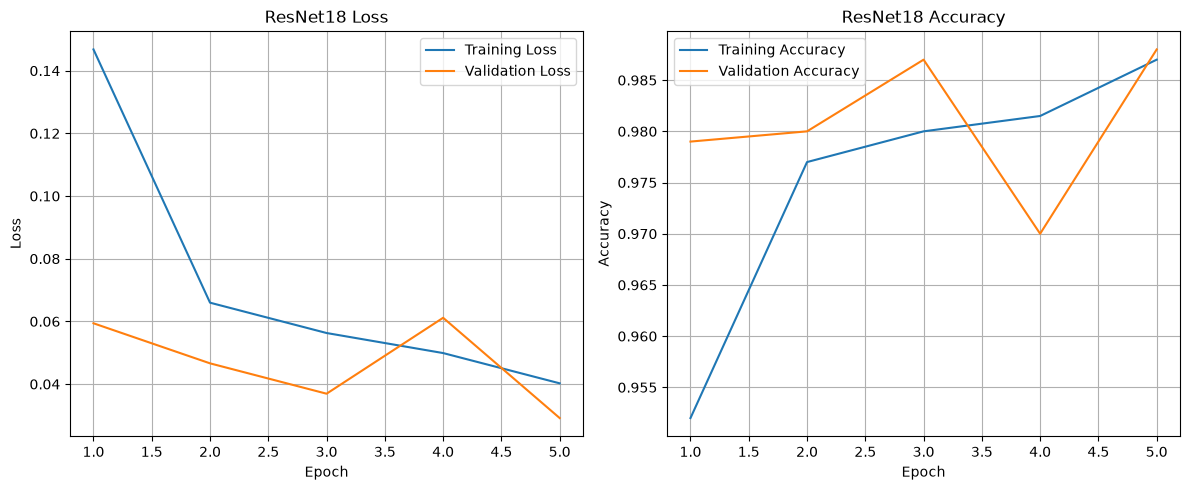

In [48]:

EPOCHS = 5
best_val_acc = 0.0

best_model_path = Path("cat_dog_resnet18_best.pth")

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================
    model.train()

    # Keep frozen backbone BatchNorm layers in evaluation mode
    # so their running statistics do not change.
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()
    model.layer4.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # =========================
    # SAVE BEST MODEL
    # =========================
    saved_message = ""

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "val_accuracy": best_val_acc,
            "class_names": class_names,
            "img_size": 224
        }, best_model_path)

        saved_message = " | Best model saved!"

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2%}"
        f"{saved_message}"
    )

# =========================
# BEST RESULT
# =========================
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

print("\nTraining completed!")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Saved model:", best_model_path.resolve())

# =========================
# PLOT CURVES
# =========================
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Training Loss")
plt.plot(epochs_range, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet18 Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label="Training Accuracy")
plt.plot(epochs_range, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet18 Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Validation accuracy: 98.80%

Classification report:
              precision    recall  f1-score   support

         Cat       0.99      0.99      0.99       500
         Dog       0.99      0.99      0.99       500

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



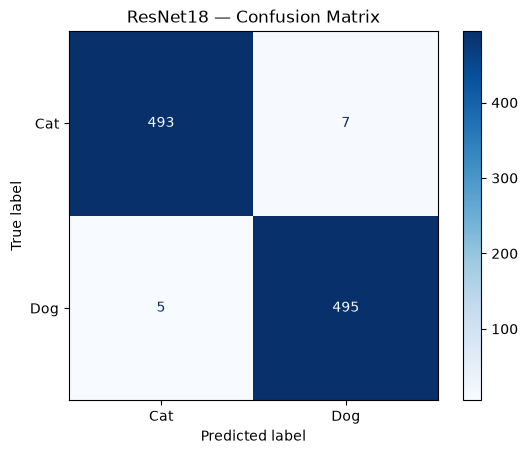

In [49]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Restore best checkpoint
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.2%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 — Confusion Matrix")
plt.show()


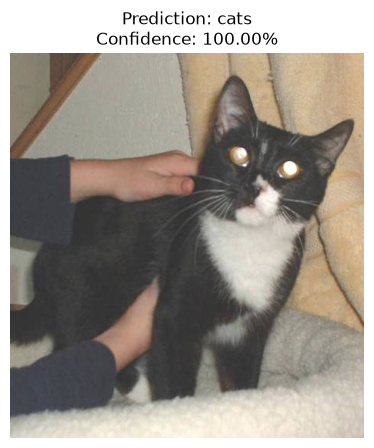

Actual class: Cat
Predicted class: cats
Confidence: 100.00%
cats: 100.00%
dogs: 0.00%


In [50]:

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

from torchvision import transforms

image_path = (
    r"C:\Users\PRAWIN KUMAR\CatvsDogFiltered"
    r"\cats_and_dogs_filtered\validation\cats\cat.2000.jpg"
)

# Read image for display
image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Cannot read image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Use the same preprocessing as ResNet18 validation
preprocess = ResNet18_Weights.DEFAULT.transforms()

image_pil = Image.fromarray(image_rgb)
image_tensor = preprocess(image_pil).unsqueeze(0).to(device)

# Predict
model.eval()

with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(image_rgb)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual class: Cat")
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[i].item() * 100:.2f}%")
